# Практика 1. Визуализация филогенетических деревьев в Python

**Курс «Молекулярная филогенетика», ИТМО**

Сегодня мы ничего не строим — мы учимся **читать, исследовать и рисовать** деревья. Алгоритмы построения будут позже, а пока задача — подружиться с деревьями, научиться задавать им вопросы и делать красивые картинки.

Что будет в ноутбуке:

0. Подготовка окружения и загрузка дерева
1. Формат Newick своими руками
2. Исследуем «Дерево жизни»: расстояния, пути, монофилия (Biopython)
3. Рисуем с matplotlib (Biopython)
4. Красивые деревья с **toytree**
5. Классика: **ete3** (по желанию)
6. Почему нельзя просто перебрать все деревья
7. Задания для самостоятельной работы

Ячейки с пометкой **✏️ Задание** — для вас. Ячейки с пометкой **🤔 Вопрос** — подумайте и ответьте текстом.

## 0. Подготовка

Если вы в Google Colab или в чистом окружении — выполните ячейку ниже. В Colab это займёт около минуты.

In [1]:
%pip install -q biopython toytree matplotlib requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 467.6/467.6 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.5/281.5 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 42.9 MB/s eta 0:00:00


In [2]:
import os
from io import StringIO
from collections import Counter

import requests
import matplotlib
import matplotlib.pyplot as plt
from Bio import Phylo
import toytree
import toyplot

import toyplot.html
from IPython.display import display, HTML

def show(canvas):
    # Показать составную картинку toyplot прямо в ноутбуке
    display(HTML(toyplot.html.tostring(canvas)))

print("Biopython и toytree загружены, toytree версии", toytree.__version__)

Biopython и toytree загружены, toytree версии 3.0.11


### Загружаем дерево

Мы будем работать с «Деревом жизни» из работы Ciccarelli et al., 2006 (*Science*): 191 организм из всех трёх доменов, построено по конкатенации 31 универсального белка (см. https://www.jasondavies.com/tree-of-life/).

Укажите в `TREE_SOURCE` **путь к файлу `life.txt`** - онлайн (https://www.jasondavies.com/tree-of-life/life.txt) или локально (файл я пришлю)

In [5]:
TREE_SOURCE = "https://www.jasondavies.com/tree-of-life/life.txt"   # <- замените на ссылку, если файла нет рядом с ноутбуком

def load_newick(source):
    # Возвращает строку Newick из локального файла или по ссылке.
    if source.startswith("http"):
        text = requests.get(source, timeout=30).text.strip()
    else:
        with open(source) as f:
            text = f.read().strip()
    # Простая защита от типичной ошибки: скачали HTML вместо дерева
    assert text.startswith("(") and text.endswith(";"), "Это не похоже на Newick. Проверьте ссылку/путь."
    return text

newick = load_newick(TREE_SOURCE)
print(f"Длина строки: {len(newick)} символов")
print(newick[:300], "...")

Длина строки: 8402 символов
(((((((((((((((((((Escherichia_coli_EDL933:0.00000,Escherichia_coli_O157_H7:0.00000)96:0.00044,((Escherichia_coli_O6:0.00000,Escherichia_coli_K12:0.00022)76:0.00022,(Shigella_flexneri_2a_2457T:0.00000,Shigella_flexneri_2a_301:0.00000)100:0.00266)75:0.00000)100:0.00813,((Salmonella_enterica:0.00000,S ...


## 1. Формат Newick своими руками

Newick — это скобочная запись дерева. Правила простые:

* `(A,B)` — A и B сестринские таксоны, у них общий предок;
* `A:0.1` — длина ветви, ведущей к A;
* `(A,B)95` — подпись внутреннего узла (часто — **поддержка**, например бутстрэп);
* в конце обязательно `;`.

In [6]:
simple = Phylo.read(StringIO("(((A,B),(C,D)),E);"), "newick")
Phylo.draw_ascii(simple)

                                                    ________________________ A
                           ________________________|
                          |                        |________________________ B
  ________________________|
 |                        |                         ________________________ C
_|                        |________________________|
 |                                                 |________________________ D
 |
 |________________________ E



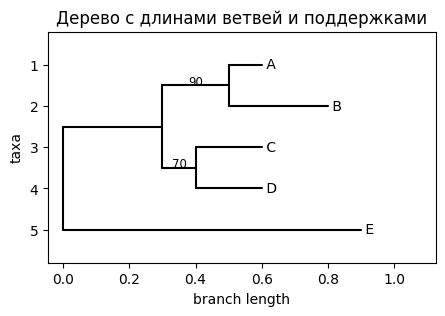

In [7]:
# Теперь с длинами ветвей и поддержками
with_lengths = Phylo.read(StringIO("(((A:0.1,B:0.3)90:0.2,(C:0.2,D:0.2)70:0.1):0.3,E:0.9);"), "newick")

fig, ax = plt.subplots(figsize=(5, 3))
Phylo.draw(with_lengths, axes=ax, do_show=False,
           branch_labels=lambda c: c.confidence)   # поддержка подписана над ветвью
ax.set_title("Дерево с длинами ветвей и поддержками")
plt.show()

### Одно и то же дерево можно записать по-разному

Узлы дерева можно «вращать», как мобиль над детской кроваткой: порядок листьев не важен. Поэтому `((A,B),(C,D))` и `((D,C),(B,A))` — **одно и то же дерево**.

Как это проверить программно? Дерево однозначно задаётся набором своих **клад** (какие листья группируются вместе). Это та же идея, на которой позже будет построено сравнение деревьев (расстояние Робинсона–Фулдса).

In [9]:
def clades_of(newick_string):
    # Набор клад: для каждого внутреннего узла - множество его листьев.
    tree = Phylo.read(StringIO(newick_string), "newick")
    n_tips = len(tree.get_terminals())
    result = set()
    for clade in tree.get_nonterminals():
        leaves = frozenset(t.name for t in clade.get_terminals())
        if len(leaves) < n_tips:          # корень (все листья) ничего не говорит
            result.add(leaves)
    return result

t1 = "(((A,B),(C,D)),E);"
t2 = "(E,((D,C),(B,A)));"
t3 = "(((A,C),(B,D)),E);"

print("t1 == t2 ?", clades_of(t1) == clades_of(t2))
print("t1 == t3 ?", clades_of(t1) == clades_of(t3))
print("Клады t1:", [sorted(c) for c in clades_of(t1)])

t1 == t2 ? True
t1 == t3 ? False
Клады t1: [['A', 'B'], ['C', 'D'], ['A', 'B', 'C', 'D']]


**✏️ Задание 1.1.** Запишите в Newick дерево для пяти животных: человек, шимпанзе, мышь, курица, акула. Сделайте это как минимум двумя способами, нарисуйте его и проверьте функцией `clades_of`, что деревья получились идентичны

In [10]:
my_tree = "((((Homo,Pan),Mus),Gallus),Shark);"   # <- исправьте, если не согласны :)
Phylo.draw_ascii(Phylo.read(StringIO(my_tree), "newick"))

                                                      _________________ Homo
                                     ________________|
                   _________________|                |_________________ Pan
                  |                 |
  ________________|                 |________________ Mus
 |                |
_|                |_________________ Gallus
 |
 |________________ Shark



## 2. Исследуем «Древо жизни»

Дерево — это не только картинка, но и структура данных, которой можно задавать вопросы.

In [12]:
tree = Phylo.read(StringIO(newick), "newick")

print("Листьев (организмов):", len(tree.get_terminals()))
print("Внутренних узлов:", len(tree.get_nonterminals()))
print("Детей у корня:", len(tree.root.clades))   # 2 => корень есть: бактерии | (археи + эукариоты)
# Внимание: tree.rooted у Biopython — просто флаг, а не свойство топологии.
# Newick не хранит информацию «укоренено/нет», поэтому флаг по умолчанию False.
print("Флаг tree.rooted:", tree.rooted)
print("Суммарная длина всех ветвей:", round(tree.total_branch_length(), 2), "замен на сайт")

Листьев (организмов): 191
Внутренних узлов: 190
Детей у корня: 2
Флаг tree.rooted: False
Суммарная длина всех ветвей: 45.54 замен на сайт


Числа во внутренних узлах этого дерева — **поддержки** (бутстрэп, %). Biopython кладёт числовые подписи в `confidence`, а текстовые — в `name`.

Узлов с поддержкой: 187 | именованные узлы: ['Bacteria']


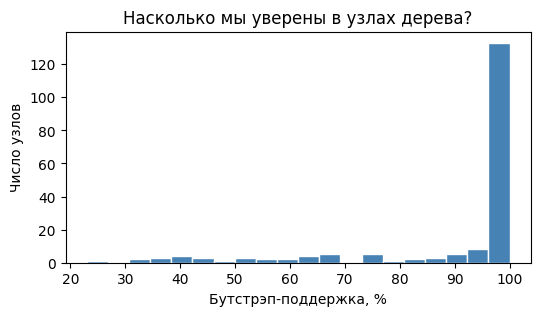

In [13]:
supports = [c.confidence for c in tree.get_nonterminals() if c.confidence is not None]
named = [c.name for c in tree.get_nonterminals() if c.name]
print("Узлов с поддержкой:", len(supports), "| именованные узлы:", named)

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(supports, bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("Бутстрэп-поддержка, %"); ax.set_ylabel("Число узлов")
ax.set_title("Насколько мы уверены в узлах дерева?")
plt.show()

**🤔 Вопрос 2.1.** Большинство узлов имеет поддержку 100, но есть и узлы с поддержкой 20–40. Где они расположены в дереве — ближе к листьям или глубоко? (Вернёмся к этому в разделе 4, когда раскрасим узлы.)

### Три домена жизни

Найдём общих предков (MRCA, most recent common ancestor) для каждого домена. Для этого достаточно двух организмов, которые точно находятся «на разных краях» домена.

In [14]:
domains = {
    "Bacteria":  ("Escherichia_coli_K12", "Bacillus_subtilis"),
    "Archaea":   ("Nanoarchaeum_equitans", "Methanosarcina_mazei"),
    "Eukaryota": ("Homo_sapiens", "Giardia_lamblia"),
}
domain_colors = {"Bacteria": "#1f77b4", "Archaea": "#d62728", "Eukaryota": "#2ca02c"}

domain_of = {}   # организм -> домен
for dom, (a, b) in domains.items():
    mrca = tree.common_ancestor(a, b)
    members = [t.name for t in mrca.get_terminals()]
    for m in members:
        domain_of[m] = dom
    print(f"{dom:10s}: {len(members):3d} организмов")

print("Все ли распределены:", len(domain_of) == len(tree.get_terminals()))

Bacteria  : 150 организмов
Archaea   :  18 организмов
Eukaryota :  23 организмов
Все ли распределены: True


### Где мы на этом дереве?

Пройдём путь от корня до человека и посмотрим, через какие узлы и с какой поддержкой он идёт.

In [15]:
path = tree.get_path("Homo_sapiens")      # список клад от корня к листу
print(f"От корня до человека {len(path)} шагов (узлов).")
for i, clade in enumerate(path):
    n = len(clade.get_terminals())
    label = clade.name or ""
    print(f"шаг {i+1:2d}: под узлом {n:3d} организмов, поддержка = {clade.confidence}, ветвь = {clade.branch_length} {label}")

От корня до человека 14 шагов (узлов).
шаг  1: под узлом  41 организмов, поддержка = None, ветвь = 0.88776 
шаг  2: под узлом  23 организмов, поддержка = 100, ветвь = 0.57543 
шаг  3: под узлом  22 организмов, поддержка = 100, ветвь = 0.10129 
шаг  4: под узлом  21 организмов, поддержка = 87, ветвь = 0.06455 
шаг  5: под узлом  18 организмов, поддержка = 44, ветвь = 0.02636 
шаг  6: под узлом  15 организмов, поддержка = 41, ветвь = 0.02708 
шаг  7: под узлом  14 организмов, поддержка = 85, ветвь = 0.04004 
шаг  8: под узлом  11 организмов, поддержка = 100, ветвь = 0.09911 
шаг  9: под узлом   9 организмов, поддержка = 95, ветвь = 0.03693 
шаг 10: под узлом   7 организмов, поддержка = 100, ветвь = 0.09688 
шаг 11: под узлом   5 организмов, поддержка = 100, ветвь = 0.01859 
шаг 12: под узлом   4 организмов, поддержка = 99, ветвь = 0.01629 
шаг 13: под узлом   2 организмов, поддержка = 100, ветвь = 0.01549 
шаг 14: под узлом   1 организмов, поддержка = None, ветвь = 0.00957 Homo_sapiens


### Кто нам ближе?

`tree.distance(a, b)` — **патристическое расстояние**: сумма длин ветвей на пути между двумя листьями (в заменах на сайт).

In [16]:
for other in ["Pan_troglodytes", "Mus_musculus", "Gallus_gallus", "Takifugu_rubripes",
              "Drosophila_melanogaster", "Saccharomyces_cerevisiae", "Arabidopsis_thaliana",
              "Escherichia_coli_K12", "Methanosarcina_mazei"]:
    print(f"{other:28s} {tree.distance('Homo_sapiens', other):.3f}")

Pan_troglodytes              0.048
Mus_musculus                 0.046
Gallus_gallus                0.087
Takifugu_rubripes            0.135
Drosophila_melanogaster      0.358
Saccharomyces_cerevisiae     0.734
Arabidopsis_thaliana         0.693
Escherichia_coli_K12         4.146
Methanosarcina_mazei         2.316


**🤔 Вопрос 2.2.** Кто ближе к человеку по расстоянию — дрожжи или арабидопсис? А по топологии (у кого с человеком более поздний общий предок)? Это одно и то же?

**🤔 Вопрос 2.3.** Посмотрите внимательно: по расстоянию **мышь ближе к человеку, чем шимпанзе**! Как такое возможно, если по топологии шимпанзе — наш ближайший родственник? Подсказка: сравните длины концевых ветвей `Homo_sapiens` и `Pan_troglodytes` (`tree.find_any(name=...).branch_length`). Почему расстояние ≠ родство, и стоит ли доверять такой длине ветви у шимпанзе?

### Самые длинные ветви

Длинная концевая ветвь означает, что последовательности этого организма сильно изменились. Запомните этих «спринтеров»: они ещё всплывут, когда мы будем говорить об артефакте **притяжения длинных ветвей** (long branch attraction).

In [ ]:
tips = sorted(tree.get_terminals(), key=lambda t: t.branch_length, reverse=True)
for t in tips[:10]:
    print(f"{t.name:35s} {t.branch_length:.3f}  ({domain_of[t.name]})")

### Монофилия: проверяем таксономию деревом

Группа **монофилетична**, если в неё входят все потомки общего предка и только они. Проверим, совпадают ли названия родов с деревом. `tree.is_monophyletic(...)` возвращает общего предка, если группа монофилетична, и `False`, если нет.

In [17]:
def genus(name):
    return name.split("_")[0]

genus_counts = Counter(genus(t.name) for t in tree.get_terminals())

def check_group(names, label):
    clades = [tree.find_any(name=n) for n in names]
    mono = tree.is_monophyletic(clades)
    if mono:
        print(f"{label:22s} МОНОФИЛЕТИЧНА ({len(names)} шт.)")
    else:
        mrca = tree.common_ancestor(*names)
        intruders = sorted({t.name for t in mrca.get_terminals()} - set(names))
        print(f"{label:22s} НЕ монофилетична; под общим предком также: {intruders[:6]}{' ...' if len(intruders) > 6 else ''}")

for g, n in genus_counts.most_common():
    if n >= 2:
        members = [t.name for t in tree.get_terminals() if genus(t.name) == g]
        check_group(members, g)

Streptococcus          МОНОФИЛЕТИЧНА (9 шт.)
Mycoplasma             НЕ монофилетична; под общим предком также: ['Ureaplasma_parvum']
Mycobacterium          МОНОФИЛЕТИЧНА (5 шт.)
Chlamydia              НЕ монофилетична; под общим предком также: ['Chlamydophila_caviae', 'Chlamydophila_pneumoniae_TW183']
Bacillus               НЕ монофилетична; под общим предком также: ['Oceanobacillus_iheyensis']
Escherichia            НЕ монофилетична; под общим предком также: ['Shigella_flexneri_2a_2457T', 'Shigella_flexneri_2a_301']
Vibrio                 МОНОФИЛЕТИЧНА (4 шт.)
Corynebacterium        МОНОФИЛЕТИЧНА (4 шт.)
Staphylococcus         МОНОФИЛЕТИЧНА (4 шт.)
Salmonella             МОНОФИЛЕТИЧНА (3 шт.)
Yersinia               МОНОФИЛЕТИЧНА (3 шт.)
Buchnera               МОНОФИЛЕТИЧНА (3 шт.)
Pseudomonas            МОНОФИЛЕТИЧНА (3 шт.)
Bordetella             МОНОФИЛЕТИЧНА (3 шт.)
Helicobacter           МОНОФИЛЕТИЧНА (3 шт.)
Prochlorococcus        НЕ монофилетична; под общим предком также: ['Syne

In [18]:
# А что насчёт «прокариот»?
prokaryotes = [n for n, d in domain_of.items() if d in ("Bacteria", "Archaea")]
check_group(prokaryotes, "Прокариоты")

Прокариоты             НЕ монофилетична; под общим предком также: ['Anopheles_gambiae', 'Arabidopsis_thaliana', 'Caenorhabditis_briggsae', 'Caenorhabditis_elegans', 'Cryptosporidium_hominis', 'Cyanidioschyzon_merolae'] ...


**🤔 Вопрос 2.4.** Какие роды оказались не монофилетичными? Для каждого предложите объяснение: устаревшая таксономия, ошибка дерева, или что-то ещё? Почему «прокариоты» — не клада, а какая это группа в терминах лекции (пара- или полифилетическая)?

## 3. Рисуем с matplotlib (Biopython)

`Phylo.draw` рисует дерево средствами matplotlib. Если задать цвет кладе, он наследуется всеми её потомками.

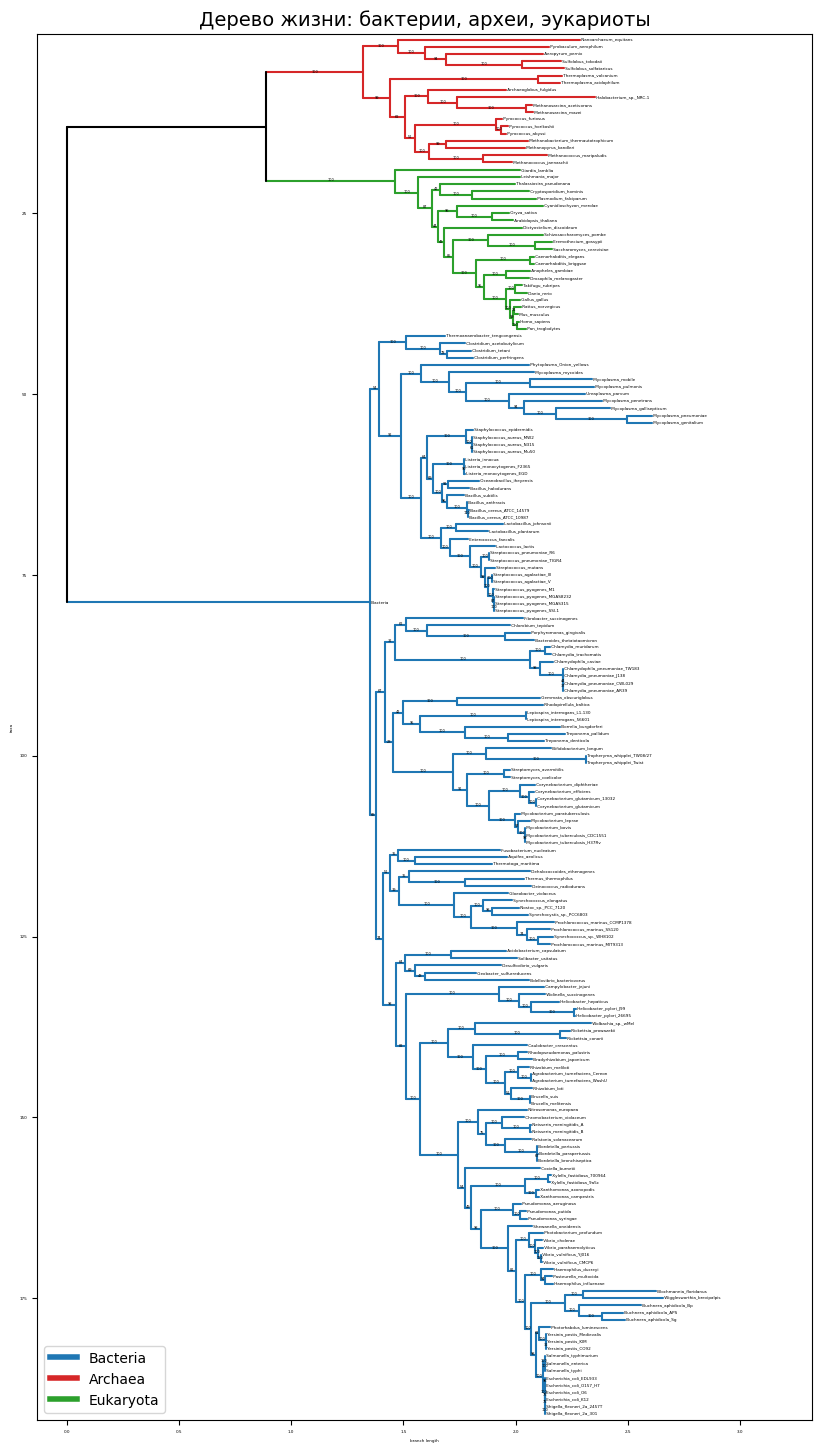

In [19]:
tree_colored = Phylo.read(StringIO(newick), "newick")
tree_colored.ladderize()   # «причёсываем»: крупные клады вниз, дерево выглядит аккуратнее

for dom, (a, b) in domains.items():
    tree_colored.common_ancestor(a, b).color = domain_colors[dom]

matplotlib.rc("font", size=3)
fig, ax = plt.subplots(figsize=(10, 18))
Phylo.draw(tree_colored, axes=ax, do_show=False)
ax.set_title("Дерево жизни: бактерии, археи, эукариоты", fontsize=14)
for dom, col in domain_colors.items():
    ax.plot([], [], color=col, lw=4, label=dom)
ax.legend(loc="lower left", fontsize=10)
matplotlib.rc("font", size=10)
fig.savefig("py_tree_domains.png", dpi=300, bbox_inches="tight")
fig.savefig("py_tree_domains.pdf", bbox_inches="tight")   # вектор — можно бесконечно увеличивать
plt.show()

191 подпись — это много. Часто полезнее вырезать интересующую часть дерева и нарисовать её крупно.

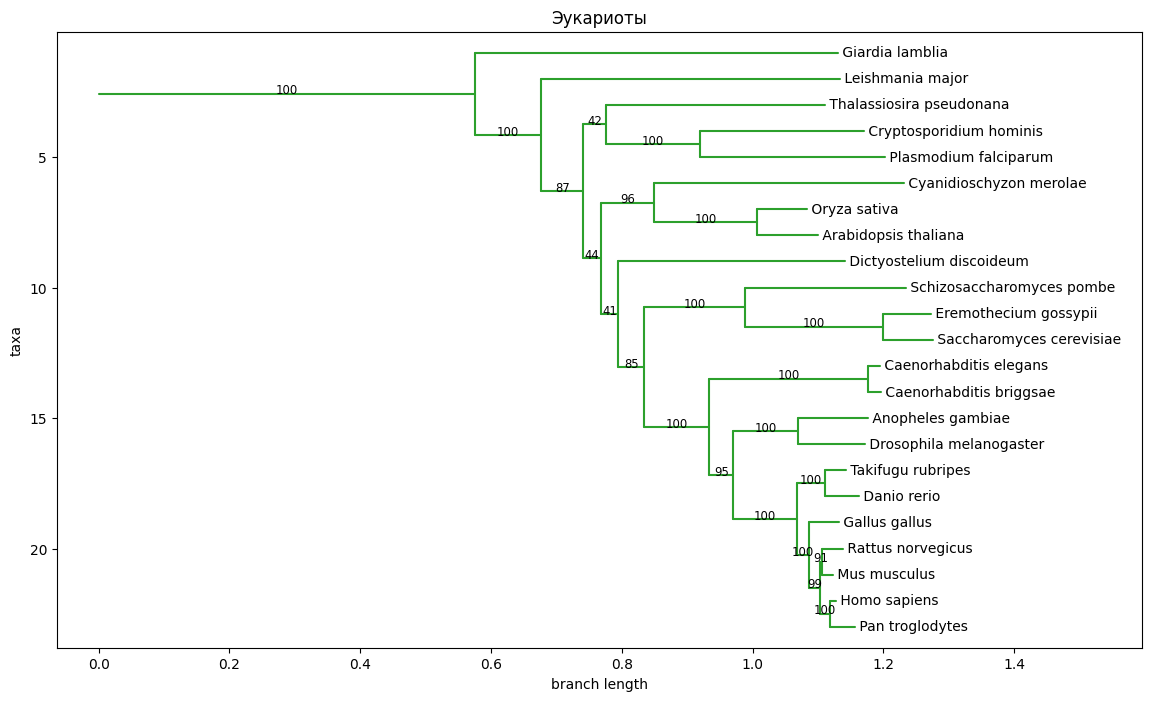

In [25]:
euk = tree_colored.common_ancestor("Homo_sapiens", "Giardia_lamblia")
euk_tree = Phylo.BaseTree.Tree(root=euk, rooted=True)

fig, ax = plt.subplots(figsize=(14, 8))
Phylo.draw(euk_tree, axes=ax, do_show=False,
           label_func=lambda c: c.name.replace("_", " ") if c.is_terminal() else None)
ax.set_title("Эукариоты")
plt.show()

**✏️ Задание 3.1.** Нарисуйте отдельно архей. Покрасьте в разные цвета Crenarchaeota (*Sulfolobus*, *Aeropyrum*, *Pyrobaculum*) и Euryarchaeota (метаногены, *Pyrococcus*, *Thermoplasma*, *Halobacterium*, *Archaeoglobus*). Куда попал *Nanoarchaeum*?

In [ ]:
# ваш код здесь

## 4. Красивые деревья с toytree

**toytree** рисует деревья в SVG/HTML: картинки чёткие, а в Jupyter они ещё и интерактивные (наведите мышь на узел, если включён `node_hover=True`).

Важная деталь: в toytree нужно явно сказать, что подписи внутренних узлов — это поддержки: `internal_labels="support"`.

In [26]:
ttree = toytree.tree(newick, internal_labels="support").ladderize()
print(ttree.ntips, "листьев,", ttree.nnodes, "узлов всего")

# Первая картинка: просто прямоугольное дерево без подписей
canvas, axes, mark = ttree.draw(tip_labels=False, width=400, height=600)

191 листьев, 381 узлов всего


<svg class="toyplot-canvas-Canvas" xmlns:toyplot="http://www.sandia.gov/toyplot" xmlns:xlink="http://www.w3.org/1999/xlink" xmlns="http://www.w3.org/2000/svg" width="400.0px" height="600.0px" viewBox="0 0 400.0 600.0" preserveAspectRatio="xMidYMid meet" style="background-color:transparent;border-color:#292724;border-style:none;border-width:1.0;fill:rgb(16.1%,15.3%,14.1%);fill-opacity:1.0;font-family:Helvetica;font-size:12px;opacity:1.0;stroke:rgb(16.1%,15.3%,14.1%);stroke-opacity:1.0;stroke-width:1.0" id="t93f005a649434889917e6247866fea37">

### Раскрашиваем домены по кругу

В toytree у каждого узла есть номер `idx`. Цвет ветви задаётся списком длины `nnodes`: элемент `i` — цвет ветви, ведущей к узлу `i`. Листья имеют номера от 0 до `ntips-1`, поэтому цвета подписей — первые `ntips` элементов того же списка.

In [28]:
edge_colors = ["#999999"] * ttree.nnodes
for dom, (a, b) in domains.items():
    mrca = ttree.get_mrca_node(a, b)
    for node in mrca.traverse():
        edge_colors[node.idx] = domain_colors[dom]

tip_colors = edge_colors[:ttree.ntips]
tip_names = [n.replace("_", " ") for n in ttree.get_tip_labels()]

canvas, axes, mark = ttree.draw(
    layout="c", edge_type="c",          # круговая раскладка (edge_type='c' обязателен для круга)
    tip_labels=tip_names,
    tip_labels_colors=tip_colors,
    tip_labels_style={"font-size": "6px"},
    tip_labels_align=False,
    edge_colors=edge_colors,
    edge_widths=1.5,
    width=900, height=900,
)
toytree.save(canvas, "toytree_domains_circle.svg")
toytree.save(canvas, "toytree_domains_circle.html")

### Насколько мы уверены в узлах?

Покажем поддержку размером и цветом точек во внутренних узлах. Слабые узлы (< 70) — красные.

In [29]:
supports = ttree.get_node_data("support").fillna(100).values
node_sizes = [0 if i < ttree.ntips else (3 + s / 15) for i, s in enumerate(supports)]
node_colors = ["#d62728" if s < 70 else "#2b2b2b" for s in supports]
node_mask = [i >= ttree.ntips for i in range(ttree.nnodes)]   # показываем только внутренние узлы

canvas, axes, mark = ttree.draw(
    tip_labels=False,
    node_mask=node_mask,
    node_sizes=node_sizes,
    node_colors=node_colors,
    node_hover=True,             # наведите мышь на узел!
    edge_colors=edge_colors,
    width=500, height=800,
)

<svg class="toyplot-canvas-Canvas" xmlns:toyplot="http://www.sandia.gov/toyplot" xmlns:xlink="http://www.w3.org/1999/xlink" xmlns="http://www.w3.org/2000/svg" width="500.0px" height="800.0px" viewBox="0 0 500.0 800.0" preserveAspectRatio="xMidYMid meet" style="background-color:transparent;border-color:#292724;border-style:none;border-width:1.0;fill:rgb(16.1%,15.3%,14.1%);fill-opacity:1.0;font-family:Helvetica;font-size:12px;opacity:1.0;stroke:rgb(16.1%,15.3%,14.1%);stroke-opacity:1.0;stroke-width:1.0" id="t55583d05a68e40a193d6562591eb9519"> idx: 191
dist: 0.3372
support: 100
height: 0.62926
name: idx: 192
dist: 0.09462
support: 94
height: 0.96646
name: idx: 193
dist: 0.12018
support: 100
height: 1.06108
name: idx: 194
dist: 0.15444
support: 100
height: 1.18126
name: idx: 195
dist: 0.66151
support: 100
height: 0.55586
name: idx: 196
dist: 0.30588
support: 100
height: 0.61138
name: idx: 197
dist: 0.12801
support: 100
height: 0.91726
name: idx: 198
dist: 0.10395
support: 100
height: 1.04527
name: idx: 199
dist: 0.02239
support: 100
height: 0.71994
name: idx: 200
dist: 0.3622
support: 100
height: 0.74233
name: idx: 201
dist: 0.07446
support: 99
height: 0.96723
name: idx: 202
dist: 0.23828
support: 100
height: 0.80341
name: idx: 203
dist: 0.06284
support: 100
height: 1.04169
name: idx: 204
dist: 0.04469
support: 51
height: 1.10453
name: idx: 205
dist: 0.06815
support: 62
height: 1.14922
name: idx: 206
dist: 0.11833
support: 99
height: 1.21737
name: idx: 207
dist: 0.43325
support: 100
height: 1.3357
name: idx: 208
dist: 0.14359
support: 100
height: 0.84914
name: idx: 209
dist: 0.03495
support: 42
height: 0.99273
name: idx: 210
dist: 0.1577
support: 100
height: 0.76229
name: idx: 211
dist: 0.08133
support: 96
height: 0.91999
name: idx: 212
dist: 0.2117
support: 100
height: 0.5688
name: idx: 213
dist: 0.1537
support: 100
height: 0.7805
name: idx: 214
dist: 0.24324
support: 100
height: 0.59185
name: idx: 215
dist: 0.0987
support: 100
height: 0.69946
name: idx: 216
dist: 0.04335
support: 100
height: 0.65793
name: idx: 217
dist: 0.00398
support: 91
height: 0.66242
name: idx: 218
dist: 0.01549
support: 100
height: 0.65091
name: idx: 219
dist: 0.01629
support: 99
height: 0.6664
name: idx: 220
dist: 0.01859
support: 100
height: 0.68269
name: idx: 221
dist: 0.09688
support: 100
height: 0.70128
name: idx: 222
dist: 0.03693
support: 95
height: 0.79816
name: idx: 223
dist: 0.09911
support: 100
height: 0.83509
name: idx: 224
dist: 0.04004
support: 85
height: 0.9342
name: idx: 225
dist: 0.02708
support: 41
height: 0.97424
name: idx: 226
dist: 0.02636
support: 44
height: 1.00132
name: idx: 227
dist: 0.06455
support: 87
height: 1.02768
name: idx: 228
dist: 0.10129
support: 100
height: 1.09223
name: idx: 229
dist: 0.57543
support: 100
height: 1.19352
name: idx: 230
dist: 0.88776
support: nan
height: 1.76895
name: idx: 231
dist: 0.03238
support: 78
height: 0.96315
name: idx: 232
dist: 0.15056
support: 100
height: 0.99553
name: idx: 233
dist: 0.11788
support: 100
height: 1.14609
name: idx: 234
dist: 0.28466
support: 100
height: 0.5941
name: idx: 235
dist: 0.31768
support: 100
height: 0.16077
name: idx: 236
dist: 0.1418
support: 100
height: 0.47845
name: idx: 237
dist: 0.06674
support: 94
height: 0.62025
name: idx: 238
dist: 0.19177
support: 100
height: 0.68699
name: idx: 239
dist: 0.07341
support: 100
height: 0.87876
name: idx: 240
dist: 0.12541
support: 100
height: 0.95217
name: idx: 241
dist: 0.09099
support: 100
height: 1.07758
name: idx: 242
dist: 0.00022
support: 61
height: 0.85257
name: idx: 243
dist: 0.02479
support: 100
height: 0.85279
name: idx: 244
dist: 0.17366
support: 100
height: 0.87758
name: idx: 245
dist: 0.00235
support: 90
height: 0.88556
name: idx: 246
dist: 0.13517
support: 100
height: 0.88791
name: idx: 247
dist: 0.02676
support: 91
height: 0.95725
name: idx: 248
dist: 0.00573
support: 100
height: 0.8692
name: idx: 249
dist: 0.08924
support: 100
height: 0.87493
name: idx: 250
dist: 0.01984
support: 96
height: 0.96417
name: idx: 25

**🤔 Вопрос 4.1.** Где сосредоточены красные (слабые) узлы? Что это говорит о том, какие части дерева жизни мы знаем хуже всего?

### Путь от корня до человека

Выделим жирной красной линией нашу эволюционную «родословную».

In [31]:
human = ttree.get_mrca_node("Homo_sapiens")
lineage = {human.idx} | {n.idx for n in human.get_ancestors()}

colors = ["#d62728" if i in lineage else "#cccccc" for i in range(ttree.nnodes)]
widths = [4 if i in lineage else 1 for i in range(ttree.nnodes)]
labels = ["Homo sapiens" if n == "Homo_sapiens" else "" for n in ttree.get_tip_labels()]

canvas, axes, mark = ttree.draw(
    layout="c", edge_type="c",
    edge_colors=colors, edge_widths=widths,
    tip_labels=labels, tip_labels_align=False,
    tip_labels_style={"font-size": "14px", "fill": "#d62728"},
    width=600, height=600,
)
toytree.save(canvas, "toytree_human_lineage.svg")

### Одно дерево — разные раскладки

Филограмма, кладограмма (без длин ветвей) и круговая раскладка — для одного поддерева (позвоночные + насекомые + нематоды).

In [32]:
animals = ttree.get_mrca_node("Homo_sapiens", "Caenorhabditis_elegans")
animal_tree = toytree.tree(animals)     # поддерево как отдельное дерево

# Кладограмма: забываем длины ветвей (все = 1) и выравниваем листья по правому краю
clado_tree = animal_tree.set_node_data("dist", default=1.0).mod.edges_extend_tips_to_align()

canvas = toyplot.Canvas(width=1100, height=420)
settings = [
    ("Филограмма",          animal_tree, dict(layout="r")),
    ("Кладограмма",         clado_tree,  dict(layout="r")),
    ("Вниз (дендрограмма)", animal_tree, dict(layout="d", tip_labels_angles=-60)),
]
for i, (title, tr, kw) in enumerate(settings):
    ax = canvas.cartesian(grid=(1, 3, i), label=title, padding=15)
    tr.draw(axes=ax, tip_labels_style={"font-size": "10px"}, **kw)
    ax.x.show = False; ax.y.show = False     # прячем оси, но оставляем заголовок
toytree.save(canvas, "toytree_layouts.svg")
show(canvas)

**🤔 Вопрос 4.2.** Чем филограмма отличается от кладограммы? Какая из них подходит, чтобы показать, что у нематод длинная ветвь? Какая — чтобы просто показать порядок ветвления?

### Случайные деревья

toytree умеет генерировать деревья. Это пригодится, когда будем проверять методы на данных с известным «правильным ответом».

In [33]:
canvas = toyplot.Canvas(width=900, height=300)
random_trees = [
    ("rtree: случайная топология",      toytree.rtree.rtree(ntips=12, seed=42)),
    ("coaltree: коалесцентное дерево",  toytree.rtree.coaltree(k=12, seed=42)),
    ("imbtree: «гребёнка»",             toytree.rtree.imbtree(ntips=12, seed=42)),
]
for i, (title, t) in enumerate(random_trees):
    ax = canvas.cartesian(grid=(1, 3, i), label=title, padding=10)
    t.draw(axes=ax, tip_labels=False)
    ax.x.show = False; ax.y.show = False
show(canvas)

**🤔 Вопрос 4.3.** `imbtree` строит максимально несбалансированное («гребёнка») дерево. Встречаются ли такие формы в реальных филогениях? Чем это может объясняться биологически?

## 5. Классика: ete3 (по желанию)

**ete3** — мощная и популярная библиотека, но ей нужен Qt. На своём компьютере с графическим интерфейсом можно использовать `t.show()` (откроется окно). На сервере и в Colab окна нет, поэтому **всегда используйте `t.render(...)`** и задавайте `QT_QPA_PLATFORM=offscreen`.

Если установка не удалась — пропустите раздел, toytree делает всё то же самое.

In [35]:
# %pip install -q ete3 PyQt5 six      # раскомментируйте при необходимости
os.environ["QT_QPA_PLATFORM"] = "offscreen"   # рисуем без дисплея

try:
    from ete3 import Tree, TreeStyle, NodeStyle
    ETE_OK = True
except Exception as e:
    ETE_OK = False
    print("ete3 недоступен, раздел можно пропустить:", e)

ete3 недоступен, раздел можно пропустить: No module named 'ete3'


In [36]:
if ETE_OK:
    et = Tree(newick, format=1)

    ts = TreeStyle()
    ts.mode = "c"              # круговое дерево
    ts.show_leaf_name = True
    ts.scale = 100

    pastel = {"Bacteria": "#dbe9f6", "Archaea": "#f6dbdb", "Eukaryota": "#dff2df"}
    for dom, (a, b) in domains.items():
        st = NodeStyle()
        st["bgcolor"] = pastel[dom]
        et.get_common_ancestor(a, b).set_style(st)

    vert = NodeStyle(); vert["bgcolor"] = "gold"
    et.get_common_ancestor("Homo_sapiens", "Danio_rerio").set_style(vert)

    et.render("ete3_tree_of_life.png", tree_style=ts, w=1200, dpi=200)
    print("Сохранено: ete3_tree_of_life.png")

In [ ]:
if ETE_OK:
    from IPython.display import Image
    display(Image("ete3_tree_of_life.png", width=700))

## 6. Почему нельзя просто перебрать все деревья?

Сколько существует укоренённых бинарных топологий для *n* видов? Ответ: $(2n-3)!! = 1 \cdot 3 \cdot 5 \cdots (2n-3)$.

In [37]:
def n_rooted_trees(n):
    result = 1
    for k in range(3, 2 * n - 2, 2):
        result *= k
    return result

for n in [3, 4, 5, 10, 20, 50, 191]:
    x = n_rooted_trees(n)
    print(f"n = {n:3d}: {x if x < 1e6 else '~10^' + str(len(str(x)) - 1)} деревьев")   # огромные числа показываем порядком

n =   3: 3 деревьев
n =   4: 15 деревьев
n =   5: 105 деревьев
n =  10: ~10^7 деревьев
n =  20: ~10^21 деревьев
n =  50: ~10^76 деревьев
n = 191: ~10^407 деревьев


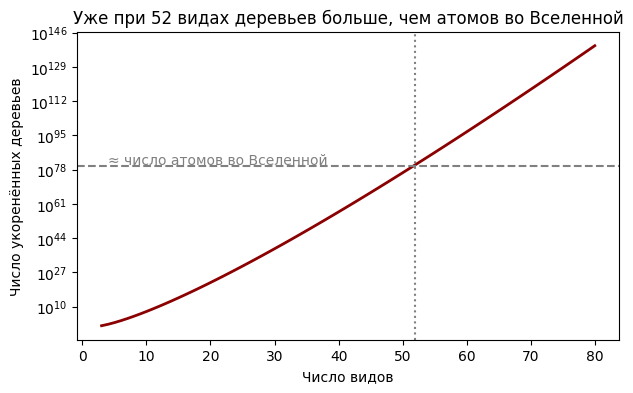

In [38]:
ns = list(range(3, 81))
counts = [float(n_rooted_trees(n)) for n in ns]

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(ns, counts, color="darkred", lw=2)
ax.axhline(1e80, ls="--", color="gray")
ax.text(4, 3e80, "≈ число атомов во Вселенной", color="gray")
first = next(n for n, c in zip(ns, counts) if c > 1e80)
ax.axvline(first, ls=":", color="gray")
ax.set_xlabel("Число видов"); ax.set_ylabel("Число укоренённых деревьев")
ax.set_title(f"Уже при {first} видах деревьев больше, чем атомов во Вселенной")
plt.show()

Вот поэтому дальше в курсе нам понадобятся **умные алгоритмы** поиска деревьев (методы расстояний, эвристики ML, MCMC), а не полный перебор.

## 7. Задания для самостоятельной работы

**✏️ 7.1. Открытка.** Сделайте самую красивую картинку дерева жизни (или его части), какую сможете: цвета, раскладка, подписи, выделенные клады. Сохраните в SVG или PDF. Лучшие работы покажем на следующем занятии.

**✏️ 7.2. Найдите себе «родственника».** Выберите любой организм из дерева (не человека). Найдите его 5 ближайших соседей по расстоянию и нарисуйте путь от корня до него, как мы сделали для человека.

**✏️ 7.3. Таксономический детектив.** Выберите один из не-монофилетичных родов из раздела 2. Нарисуйте поддерево с его общим предком и выделите цветом представителей рода. Объясните в 2–3 предложениях, почему так могло получиться.

**✏️ 7.4. Поддержки.** Нарисуйте только поддерево эукариот, подписав поддержку у каждого внутреннего узла (подсказка: аргумент `node_labels="support"` в toytree). Какие отношения внутри эукариот наименее надёжны?

In [ ]:
# ваш код здесь